
# Ride-Sharing Demand & Revenue Intelligence

## Exploratory Data Analysis (SQL + Python)

### Dataset
NYC Yellow Taxi Trip Records — August 2026

### Objective
Analyze taxi demand patterns, passenger charge distribution,
travel behavior, pickup locations, and borough-level activity.

### Analysis
- Hourly demand and revenue
- Weekday vs weekend patterns
- Top pickup zones
- Borough-level performance
- Hypothetical surge pricing simulation
- Power BI dataset preparation


## Dataset Loading and SQL Connection

In [2]:

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


## Load Cleaned August 2026 Dataset

In [3]:

filename = "Cleaned_yellow_tripdata_2026-08.parquet"

possible_paths = [
    Path(filename),
    Path("Processed") / filename,
    Path("../Processed") / filename
]

file_path = next(
    (p for p in possible_paths if p.is_file()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Cleaned dataset not found. Run Notebook 01 first."
    )

df = pd.read_parquet(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (3163242, 27)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,pickup_hour,pickup_day,pickup_weekday,is_weekend,revenue_per_mile,revenue_per_minute,tip_percentage
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140,262,1,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333,0,1,5,1,23.00,2.89,0.3538
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140,262,1,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333,0,1,5,1,21.36,2.83,0.5308
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,140,263,1,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667,0,1,5,1,14.09,2.47,0.3291
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164,80,1,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667,0,1,5,1,9.80,1.91,0.2892
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148,141,1,20.5,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000,0,1,5,1,8.82,1.48,0.2561


## Establish DuckDB Connection

In [4]:

connection = duckdb.connect()

connection.register("taxi", df)

print("DuckDB connection established successfully!")


DuckDB connection established successfully!


# Hourly Demand and Revenue
## Hourly Demand Analysis Using SQL

In [6]:

query = """
SELECT
    pickup_hour,
    COUNT(*) AS total_trips,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    ROUND(AVG(fare_amount), 2) AS avg_fare,
    ROUND(AVG(tip_amount), 2) AS avg_tip,
    ROUND(AVG(trip_duration_min), 2) AS avg_trip_duration
FROM taxi
GROUP BY pickup_hour
ORDER BY pickup_hour
"""

hourly_df = connection.execute(query).df()

display(hourly_df)


,pickup_hour,total_trips,total_revenue,avg_fare,avg_tip,avg_trip_duration
0,0,111361,3490439.74,22.84,2.15,17.18
1,1,79847,2368277.57,21.75,1.79,16.42
2,2,54179,1576487.85,21.49,1.58,15.94
3,3,37720,1115749.67,22.03,1.49,15.74
4,4,30048,975922.66,24.55,1.56,16.45
5,5,31239,1052223.84,25.05,1.96,16.36
6,6,55395,1687846.47,22.54,1.97,15.79
7,7,85811,2526182.30,21.26,2.37,15.88
8,8,118858,3423424.87,20.69,2.44,16.83
9,9,130792,3708672.80,19.95,2.71,16.88


## Trips by Hour

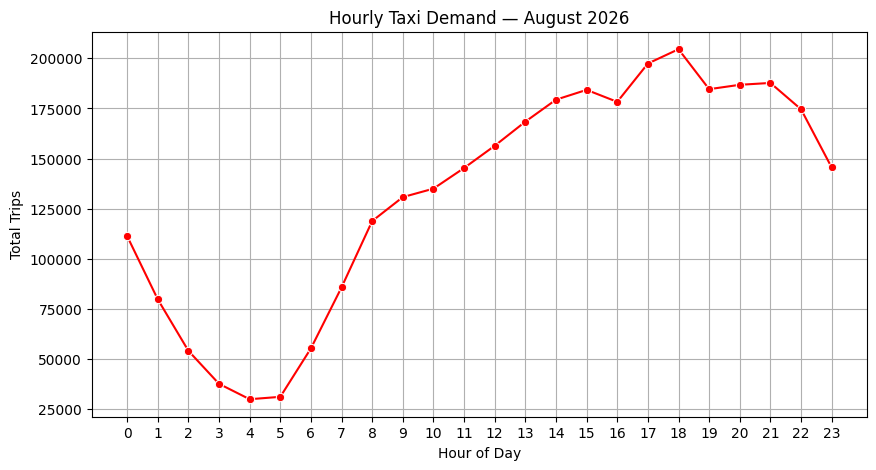

In [7]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_df,
    x="pickup_hour",
    y="total_trips",
    marker="o",
    color="red"
)

plt.title("Hourly Taxi Demand — August 2026")
plt.xlabel("Hour of Day")
plt.ylabel("Total Trips")
plt.xticks(range(24))
plt.grid(True)
plt.show()


## Highest and Lowest Demand

In [8]:

peak_demand = hourly_df.loc[
    hourly_df["total_trips"].idxmax()
]

lowest_demand = hourly_df.loc[
    hourly_df["total_trips"].idxmin()
]

print("Highest demand hour:", peak_demand["pickup_hour"])
print("Highest total trips:", peak_demand["total_trips"])

print("Lowest demand hour:", lowest_demand["pickup_hour"])
print("Lowest total trips:", lowest_demand["total_trips"])

print("Median hourly trips:", hourly_df["total_trips"].median())


Highest demand hour: 18.0
Highest total trips: 204503.0
Lowest demand hour: 4.0
Lowest total trips: 30048.0
Median hourly trips: 145423.0


## Revenue by Hour

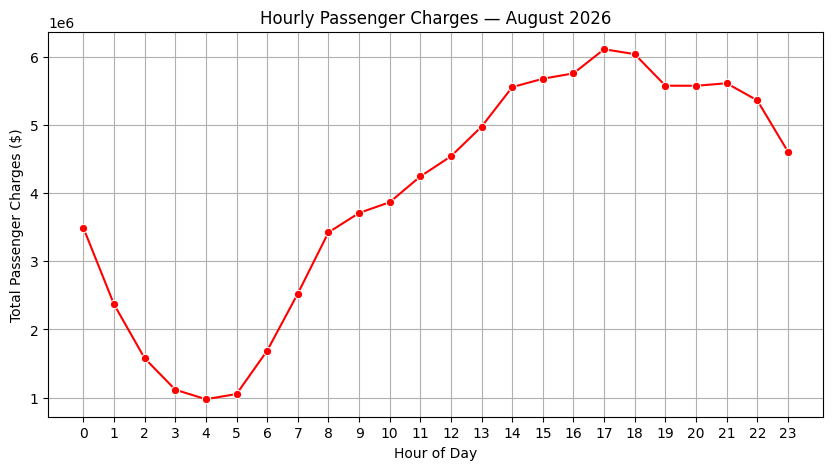

In [9]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_df,
    x="pickup_hour",
    y="total_revenue",
    marker="o",
    color="red"
)

plt.title("Hourly Passenger Charges — August 2026")
plt.xlabel("Hour of Day")
plt.ylabel("Total Passenger Charges ($)")
plt.xticks(range(24))
plt.grid(True)
plt.show()


## Highest and Lowest Revenue

In [10]:

highest_revenue = hourly_df.loc[
    hourly_df["total_revenue"].idxmax()
]

lowest_revenue = hourly_df.loc[
    hourly_df["total_revenue"].idxmin()
]

print("Highest revenue hour:", highest_revenue["pickup_hour"])
print("Highest revenue ($):", highest_revenue["total_revenue"])

print("Lowest revenue hour:", lowest_revenue["pickup_hour"])
print("Lowest revenue ($):", lowest_revenue["total_revenue"])

print("Median hourly revenue ($):",
      hourly_df["total_revenue"].median())


Highest revenue hour: 17.0
Highest revenue ($): 6111374.05
Lowest revenue hour: 4.0
Lowest revenue ($): 975922.66
Median hourly revenue ($): 4392337.0600000005


## Average Revenue per Trip

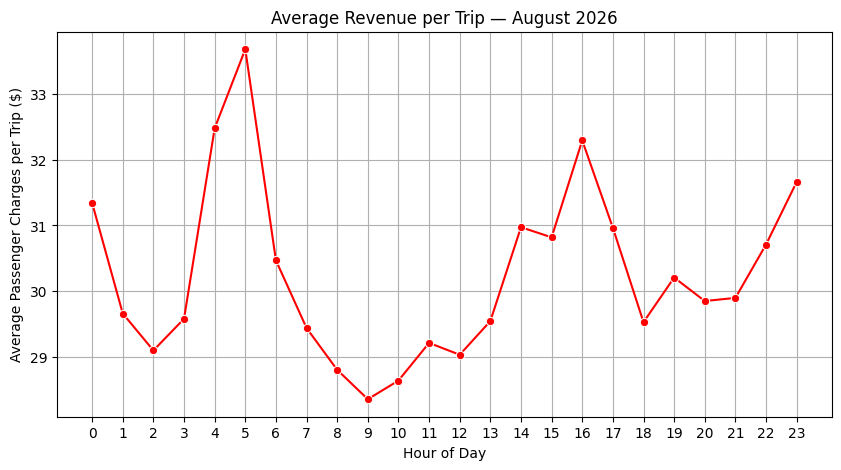

,pickup_hour,revenue_per_trip
5,5,33.683019
4,4,32.478789
16,16,32.294932
23,23,31.663007
0,0,31.343466
14,14,30.973995
17,17,30.964204
15,15,30.819281
22,22,30.710446
6,6,30.469293


In [13]:

hourly_df["revenue_per_trip"] = (
    hourly_df["total_revenue"] /
    hourly_df["total_trips"]
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_df,
    x="pickup_hour",
    y="revenue_per_trip",
    marker="o",
    color="red"
)

plt.title("Average Revenue per Trip — August 2026")
plt.xlabel("Hour of Day")
plt.ylabel("Average Passenger Charges per Trip ($)")
plt.xticks(range(24))
plt.grid(True)
plt.show()

display(
    hourly_df[
        ["pickup_hour", "revenue_per_trip"]
    ].sort_values("revenue_per_trip", ascending=False)
)


# Weekend vs Weekday Analysis
## Weekend vs Weekday Using SQL

In [14]:

query = """
SELECT
    is_weekend,
    COUNT(*) AS total_trips,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    ROUND(AVG(fare_amount), 2) AS avg_fare,
    ROUND(AVG(trip_distance), 2) AS avg_distance,
    ROUND(AVG(trip_duration_min), 2) AS avg_duration,
    ROUND(AVG(tip_percentage), 2) AS avg_tip_percentage,
    CASE
        WHEN is_weekend = 0 THEN 'Weekday'
        ELSE 'Weekend'
    END AS day_type
FROM taxi
GROUP BY is_weekend
ORDER BY is_weekend
"""

weekend_df = connection.execute(query).df()

display(weekend_df)


,is_weekend,total_trips,total_revenue,avg_fare,avg_distance,avg_duration,avg_tip_percentage,day_type
0,0,2098434,63435711.51,20.84,5.09,17.39,0.17,Weekday
1,1,1064808,31989039.95,21.71,5.17,17.64,0.14,Weekend


## Total Trips: Weekend vs Weekday

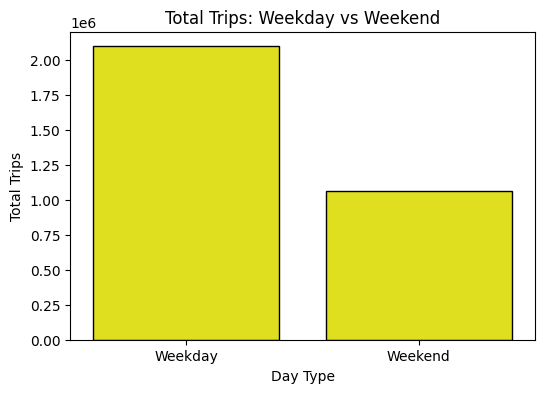

In [15]:

plt.figure(figsize=(6, 4))

sns.barplot(
    data=weekend_df,
    x="day_type",
    y="total_trips",
    color="yellow",
    edgecolor="black"
)

plt.title("Total Trips: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Total Trips")
plt.show()


## Total Revenue: Weekend vs Weekday

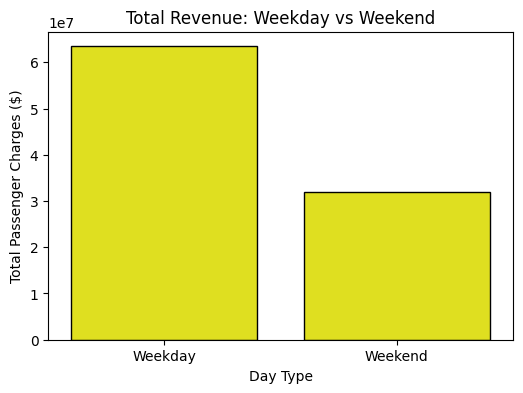

In [16]:

plt.figure(figsize=(6, 4))

sns.barplot(
    data=weekend_df,
    x="day_type",
    y="total_revenue",
    color="yellow",
    edgecolor="black"
)

plt.title("Total Revenue: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Total Passenger Charges ($)")
plt.show()


## Average Fare: Weekend vs Weekday

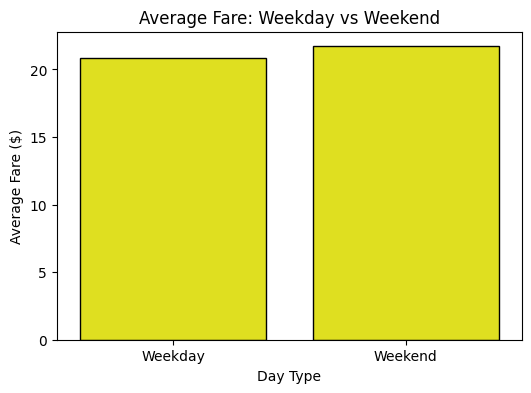

In [17]:

plt.figure(figsize=(6, 4))

sns.barplot(
    data=weekend_df,
    x="day_type",
    y="avg_fare",
    color="yellow",
    edgecolor="black"
)

plt.title("Average Fare: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Fare ($)")
plt.show()


## Average Trip Duration: Weekend vs Weekday

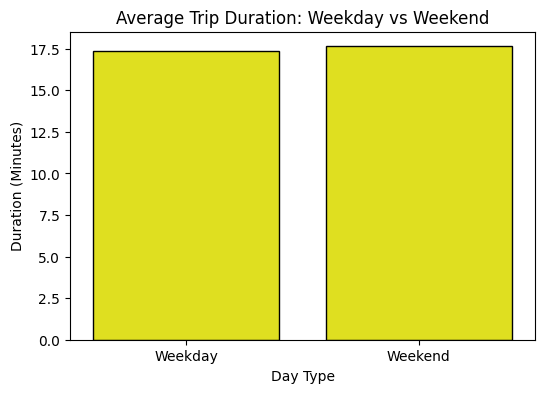

In [18]:

plt.figure(figsize=(6, 4))

sns.barplot(
    data=weekend_df,
    x="day_type",
    y="avg_duration",
    color="yellow",
    edgecolor="black"
)

plt.title("Average Trip Duration: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Duration (Minutes)")
plt.show()


## Average Tip Percentage: Weekend vs Weekday

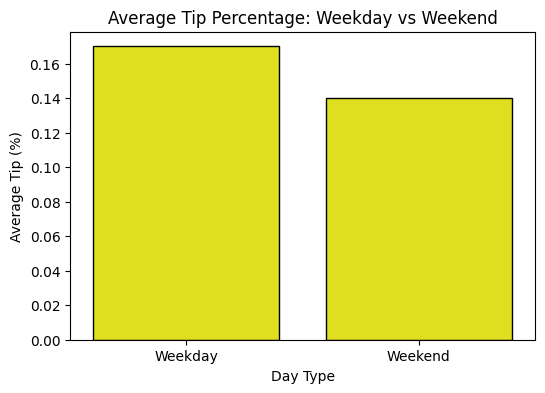

In [19]:

plt.figure(figsize=(6, 4))

sns.barplot(
    data=weekend_df,
    x="day_type",
    y="avg_tip_percentage",
    color="yellow",
    edgecolor="black"
)

plt.title("Average Tip Percentage: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Tip (%)")
plt.show()


# Zone-Level Revenue Intelligence
## Load Taxi Zone Lookup Data

In [21]:

import pandas as pd

zones = pd.read_csv("taxi_zone_lookup.csv")

display(zones.head())




,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [22]:

connection.register("zones", zones)

print("Taxi zone lookup connected successfully!")


Taxi zone lookup connected successfully!


## Top Pickup Zones by Revenue



In [27]:


query = """
select
    z.Borough,
    z.Zone,
    count(*) as total_trips,
    sum(t.total_amount) as total_revenue,
    round(avg(t.total_amount), 2) as avg_revenue_per_trip
from taxi t
join zones z
on t.PULocationID = z.LocationID
group by z.Borough, z.Zone
order by total_revenue desc
limit 10
"""

top_zones = connection.execute(query).df()
top_zones



,Borough,Zone,total_trips,total_revenue,avg_revenue_per_trip
0,Queens,JFK Airport,146831,11394620.39,77.60
1,Queens,LaGuardia Airport,85211,5836530.85,68.50
2,Manhattan,Midtown Center,130683,3450251.29,26.40
3,Manhattan,Penn Station/Madison Sq West,111885,3000116.54,26.81
4,Manhattan,Times Sq/Theatre District,92672,2749607.96,29.67
5,Manhattan,Upper East Side South,122543,2648298.68,21.61
6,Manhattan,East Chelsea,87122,2436493.61,27.97
7,Manhattan,Midtown East,95897,2432553.88,25.37
8,Manhattan,East Village,90907,2324490.08,25.57
9,Manhattan,Upper East Side North,100018,2241291.73,22.41


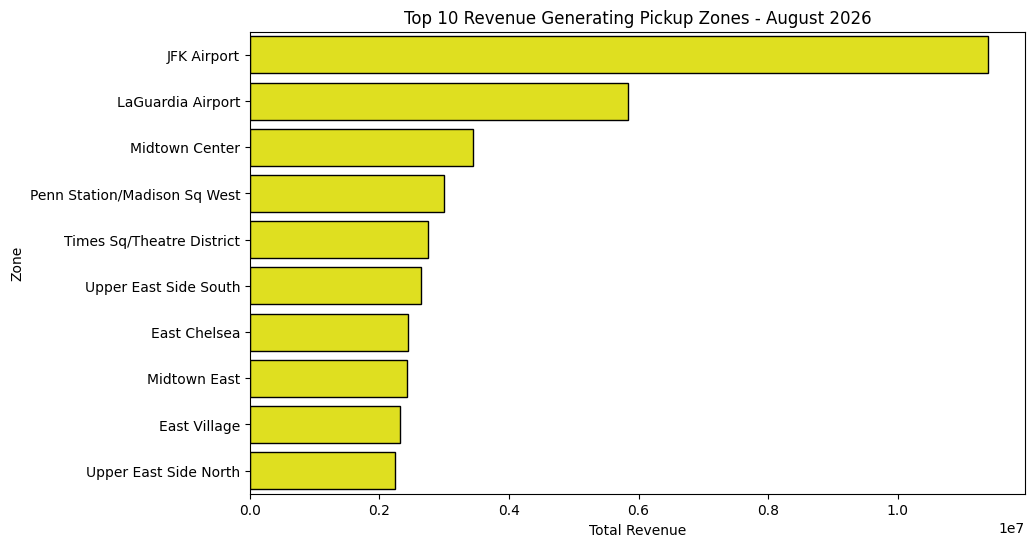

In [28]:

plt.figure(figsize=(10,6))
sns.barplot(data=top_zones, y="Zone", x="total_revenue", color="yellow", edgecolor="black")

plt.title("Top 10 Revenue Generating Pickup Zones - August 2026")
plt.xlabel("Total Revenue")
plt.ylabel("Zone")
plt.show()


## Borough-Level Analysis

In [29]:

query = """
select
    z.Borough,
    count(*) as total_trips,
    sum(t.total_amount) as total_revenue,
    round(avg(t.total_amount), 2) as avg_revenue_per_trip
from taxi t
join zones z
on t.PULocationID = z.LocationID
group by z.Borough
order by total_revenue desc
"""

borough = connection.execute(query).df()
borough


,Borough,total_trips,total_revenue,avg_revenue_per_trip
0,Manhattan,2749586,7.087620e+07,25.78
1,Queens,300527,2.033280e+07,67.66
2,Brooklyn,95583,3.498583e+06,36.60
3,Bronx,13826,5.106526e+05,36.93
4,None,843,9.027086e+04,107.08
5,Unknown,2434,8.626978e+04,35.44
6,EWR,121,1.516034e+04,125.29
7,Staten Island,322,1.481281e+04,46.00


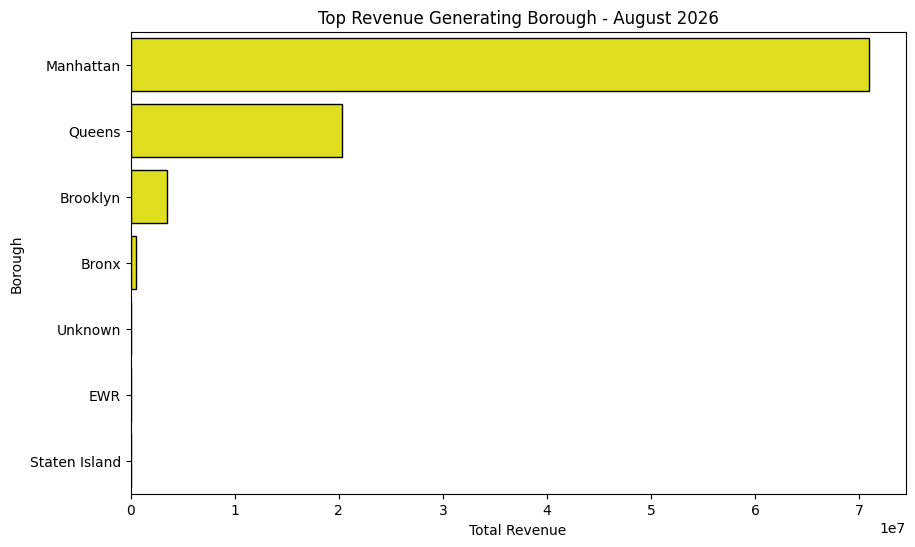

In [30]:

plt.figure(figsize=(10,6))
sns.barplot(data=borough, y="Borough", x="total_revenue",
            color="yellow", edgecolor="black")

plt.title("Top Revenue Generating Borough - August 2026")
plt.xlabel("Total Revenue")
plt.ylabel("Borough")
plt.show()


## Hourly Demand Percentile

In [31]:

hourly_df["demand_percentile"] = round(
    hourly_df["total_trips"].rank(pct=True) * 100, 2
)

hourly_df


,pickup_hour,total_trips,total_revenue,avg_fare,avg_tip,avg_trip_duration,revenue_per_trip,demand_percentile
0,0,111361,3490439.74,22.84,2.15,17.18,31.343466,33.33
1,1,79847,2368277.57,21.75,1.79,16.42,29.660195,25.00
2,2,54179,1576487.85,21.49,1.58,15.94,29.097766,16.67
3,3,37720,1115749.67,22.03,1.49,15.74,29.579790,12.50
4,4,30048,975922.66,24.55,1.56,16.45,32.478789,4.17
5,5,31239,1052223.84,25.05,1.96,16.36,33.683019,8.33
6,6,55395,1687846.47,22.54,1.97,15.79,30.469293,20.83
7,7,85811,2526182.30,21.26,2.37,15.88,29.438910,29.17
8,8,118858,3423424.87,20.69,2.44,16.83,28.802646,37.50
9,9,130792,3708672.80,19.95,2.71,16.88,28.355502,41.67


## Surge Multiplier

In [32]:

def surge_multiplier(p):
    if p < 75:
        return 1.0
    elif p < 85:
        return 1.2
    elif p < 95:
        return 1.5
    else:
        return 2.0

hourly_df["surge_multiplier"] = (
    hourly_df["demand_percentile"].apply(surge_multiplier)
)

hourly_df


,pickup_hour,total_trips,total_revenue,avg_fare,avg_tip,avg_trip_duration,revenue_per_trip,demand_percentile,surge_multiplier
0,0,111361,3490439.74,22.84,2.15,17.18,31.343466,33.33,1.0
1,1,79847,2368277.57,21.75,1.79,16.42,29.660195,25.00,1.0
2,2,54179,1576487.85,21.49,1.58,15.94,29.097766,16.67,1.0
3,3,37720,1115749.67,22.03,1.49,15.74,29.579790,12.50,1.0
4,4,30048,975922.66,24.55,1.56,16.45,32.478789,4.17,1.0
5,5,31239,1052223.84,25.05,1.96,16.36,33.683019,8.33,1.0
6,6,55395,1687846.47,22.54,1.97,15.79,30.469293,20.83,1.0
7,7,85811,2526182.30,21.26,2.37,15.88,29.438910,29.17,1.0
8,8,118858,3423424.87,20.69,2.44,16.83,28.802646,37.50,1.0
9,9,130792,3708672.80,19.95,2.71,16.88,28.355502,41.67,1.0


## Surge Revenue per Hour

In [33]:

hourly_df["surge_revenue"] = (
    hourly_df["total_revenue"] * hourly_df["surge_multiplier"]
)

hourly_df


,pickup_hour,total_trips,total_revenue,avg_fare,avg_tip,avg_trip_duration,revenue_per_trip,demand_percentile,surge_multiplier,surge_revenue
0,0,111361,3490439.74,22.84,2.15,17.18,31.343466,33.33,1.0,3.490440e+06
1,1,79847,2368277.57,21.75,1.79,16.42,29.660195,25.00,1.0,2.368278e+06
2,2,54179,1576487.85,21.49,1.58,15.94,29.097766,16.67,1.0,1.576488e+06
3,3,37720,1115749.67,22.03,1.49,15.74,29.579790,12.50,1.0,1.115750e+06
4,4,30048,975922.66,24.55,1.56,16.45,32.478789,4.17,1.0,9.759227e+05
5,5,31239,1052223.84,25.05,1.96,16.36,33.683019,8.33,1.0,1.052224e+06
6,6,55395,1687846.47,22.54,1.97,15.79,30.469293,20.83,1.0,1.687846e+06
7,7,85811,2526182.30,21.26,2.37,15.88,29.438910,29.17,1.0,2.526182e+06
8,8,118858,3423424.87,20.69,2.44,16.83,28.802646,37.50,1.0,3.423425e+06
9,9,130792,3708672.80,19.95,2.71,16.88,28.355502,41.67,1.0,3.708673e+06


## Surge (Before vs After) Analysis

In [34]:

original_revenue = hourly_df["total_revenue"].sum()
surge_revenue = hourly_df["surge_revenue"].sum()

increase_percentage = round(
    ((surge_revenue - original_revenue) / original_revenue) * 100,
    2
)

print("revenue before surge :", original_revenue)
print()
print("revenue after surge :", surge_revenue)
print()
print("percentage change :", str(increase_percentage) + " %")


revenue before surge : 95424751.46000001

revenue after surge : 116530084.817

percentage change : 22.12 %


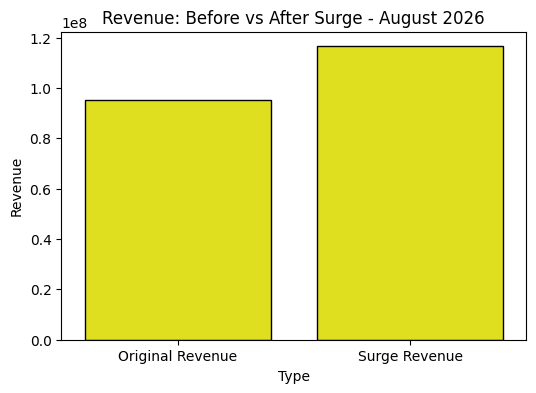

In [35]:

surge_df = pd.DataFrame({
    "Type": ["Original Revenue", "Surge Revenue"],
    "Revenue": [original_revenue, surge_revenue]
})

plt.figure(figsize=(6,4))
sns.barplot(data=surge_df, x="Type", y="Revenue",
            color="yellow", edgecolor="black")

plt.title("Revenue: Before vs After Surge - August 2026")
plt.show()


## For Power BI

In [36]:

final_df = df.copy()

# Merging surge multiplier by hour
final_df = final_df.merge(
    hourly_df[["pickup_hour", "surge_multiplier"]],
    on="pickup_hour",
    how="left"
)

# Calculating simulated surge fare
final_df["simulated_total_amount"] = (
    final_df["total_amount"] *
    final_df["surge_multiplier"]
)

final_df.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,pickup_hour,pickup_day,pickup_weekday,is_weekend,revenue_per_mile,revenue_per_minute,tip_percentage,surge_multiplier,simulated_total_amount
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140,262,1,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333,0,1,5,1,23.00,2.89,0.3538,1.0,13.80
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140,262,1,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333,0,1,5,1,21.36,2.83,0.5308,1.0,14.95
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,140,263,1,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667,0,1,5,1,14.09,2.47,0.3291,1.0,15.50
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164,80,1,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667,0,1,5,1,9.80,1.91,0.2892,1.0,51.37
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148,141,1,20.5,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000,0,1,5,1,8.82,1.48,0.2561,1.0,31.50


## Saving Final Dataset

In [ ]:

output_file = (
    file_path.resolve().parent / "final_yellow_tripdata_2026-08.csv"
)

final_df.to_csv(output_file, index=False)
